# EDA

In [62]:
# importing libraries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats
from scipy.stats import shapiro

In [2]:
# laoding data
df = pd.read_csv('../data/train.csv')
df

,airline,date_of_journey,source,destination,dep_time,arrival_time,duration,total_stops,additional_info,price
0,Multiple Carriers,2019-05-27,Delhi,Cochin,11:40:00,19:00:00,440,1,No Info,9794
1,Jet Airways,2019-06-09,Banglore,Delhi,15:15:00,18:10:00,175,0,In-Flight Meal Not Included,7229
2,Air India,2019-05-24,Mumbai,Hyderabad,13:55:00,15:25:00,90,0,No Info,3100
3,Jet Airways,2019-05-24,Kolkata,Banglore,14:05:00,19:50:00,345,1,In-Flight Meal Not Included,10844
4,Spicejet,2019-05-21,Delhi,Cochin,08:45:00,13:15:00,270,1,No Check-In Baggage Included,5158
...,...,...,...,...,...,...,...,...,...,...
8364,Jet Airways,2019-03-24,Kolkata,Banglore,18:55:00,12:00:00,1025,1,In-Flight Meal Not Included,11134
8365,Vistara,2019-05-09,Banglore,Delhi,17:00:00,19:35:00,155,0,No Info,4878
8366,Multiple Carriers,2019-05-09,Delhi,Cochin,12:50:00,01:30:00,760,1,No Info,34273
8367,Goair,2019-05-15,Banglore,Delhi,07:45:00,10:40:00,175,0,No Info,3419


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8369 entries, 0 to 8368
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   airline          8369 non-null   str  
 1   date_of_journey  8369 non-null   str  
 2   source           8369 non-null   str  
 3   destination      8369 non-null   str  
 4   dep_time         8369 non-null   str  
 5   arrival_time     8369 non-null   str  
 6   duration         8369 non-null   int64
 7   total_stops      8369 non-null   int64
 8   additional_info  8369 non-null   str  
 9   price            8369 non-null   int64
dtypes: int64(3), str(7)
memory usage: 654.0 KB


In [4]:
# fixing data types
def fix_datetime(df):

    return df.assign(

        date_of_journey = lambda df_: pd.to_datetime(df_['date_of_journey'], dayfirst=True, format='mixed'),
        
        dep_time = lambda df_ : pd.to_datetime(df_['dep_time'], format='mixed'),
        arrival_time = lambda df_ : pd.to_datetime(df_['arrival_time'], format='mixed')
    )

df = fix_datetime(df)

## Data Analysis

In [5]:
df.describe(include='number')

,duration,total_stops,price
count,8369.000000,8369.000000,8369.000000
mean,628.675469,0.802246,9042.225594
std,500.579658,0.660780,4665.359862
min,75.000000,0.000000,1759.000000
25%,170.000000,0.000000,5224.000000
50%,505.000000,1.000000,8266.000000
75%,910.000000,1.000000,12347.000000
max,2860.000000,4.000000,79512.000000


In [6]:
df.describe(include='str')

,airline,source,destination,additional_info
count,8369,8369,8369,8369
unique,9,5,6,9
top,Jet Airways,Delhi,Cochin,No Info
freq,2977,3456,3456,6565


In [7]:
df.isnull().sum()

airline            0
date_of_journey    0
source             0
destination        0
dep_time           0
arrival_time       0
duration           0
total_stops        0
additional_info    0
price              0
dtype: int64

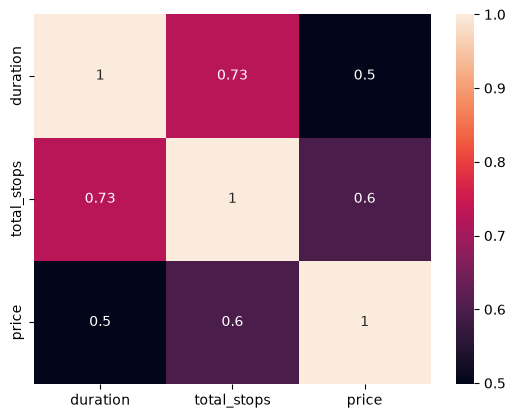

In [8]:
sns.heatmap(df.corr(numeric_only=True), annot=True)
plt.show()

### Airline

In [9]:
df['airline'].unique()

<StringArray>
['Multiple Carriers',       'Jet Airways',         'Air India',
          'Spicejet',           'Vistara',            'Indigo',
             'Goair',          'Air Asia',            'Trujet']
Length: 9, dtype: str

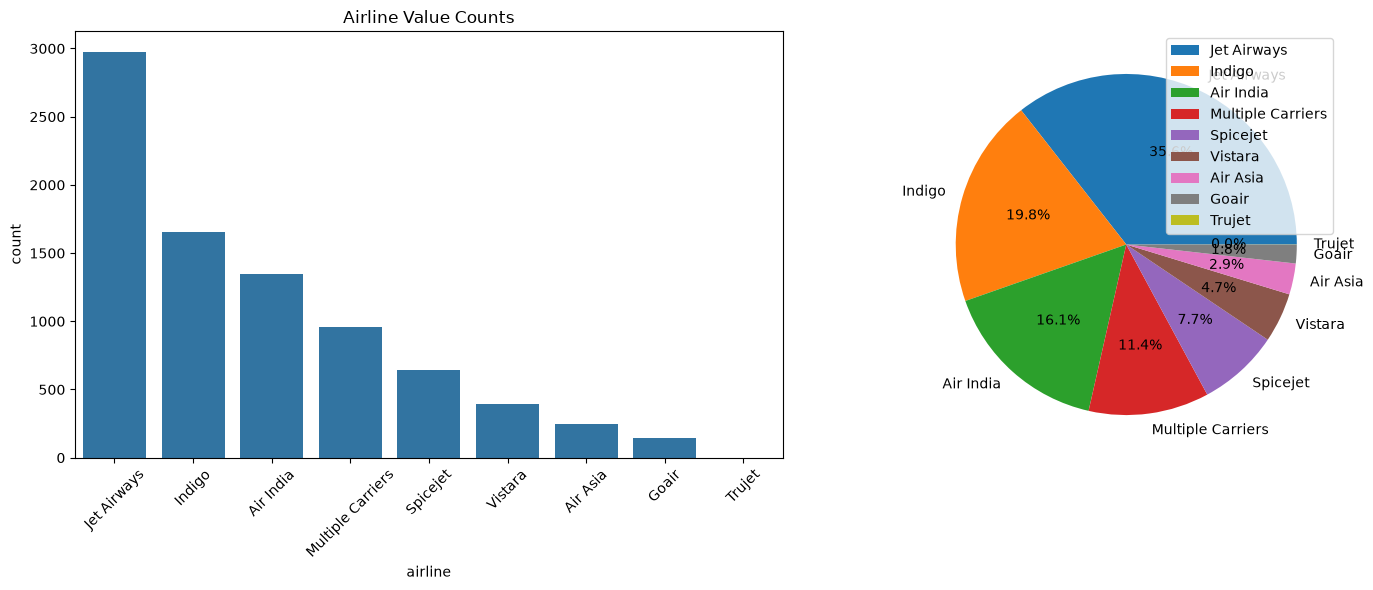

In [10]:
plt.figure(figsize=(15, 6))
plt.subplot(1, 2, 1)
sns.barplot(df.airline.value_counts())
plt.xticks(rotation=45)
plt.title('Airline Value Counts')

plt.subplot(1, 2, 2)
plt.pie(df.airline.value_counts(), labels=df.airline.value_counts().index, autopct='%.1f%%',normalize=True)
plt.legend()
plt.tight_layout()
plt.show()

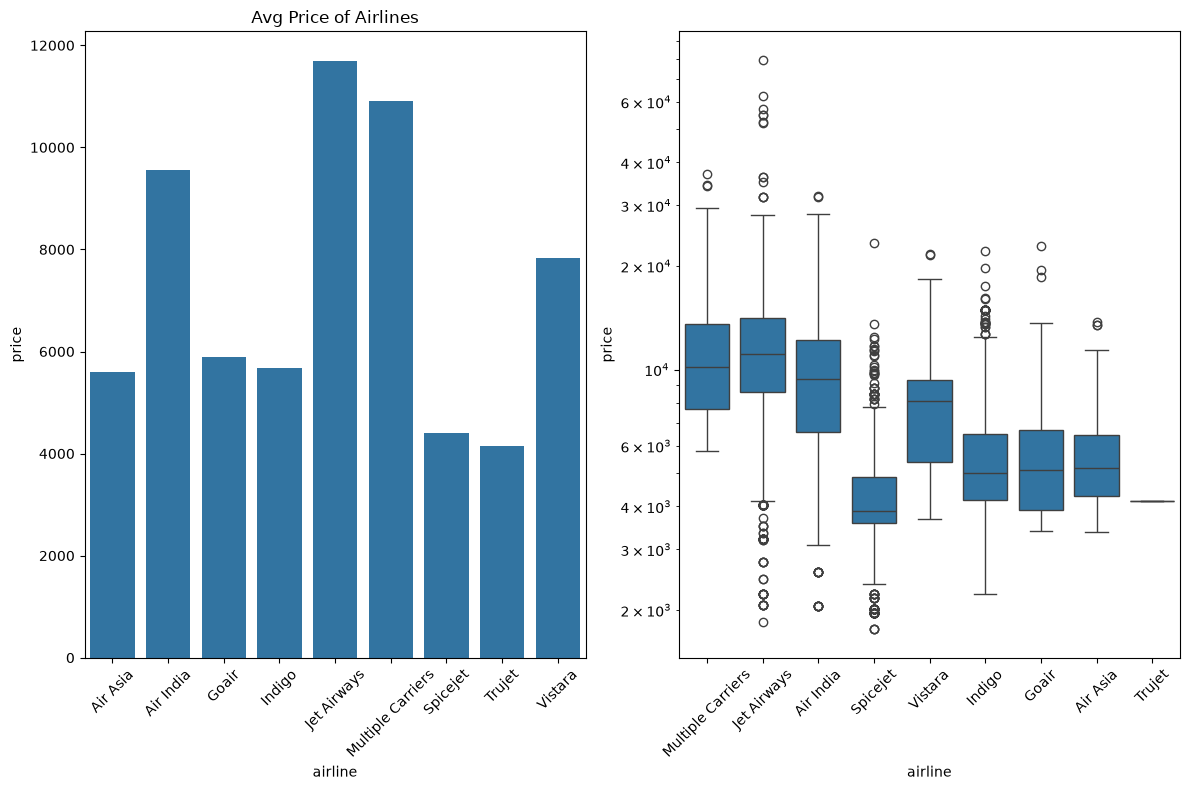

In [11]:
plt.figure(figsize=(12, 8))

plt.subplot(1, 2, 1)
sns.barplot(df.groupby('airline')['price'].mean())
plt.xticks(rotation=45)
plt.title('Avg Price of Airlines')

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='airline', y='price', log_scale=True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Date of Journey

In [12]:
df['date_of_journey'].head()

0   2019-05-27
1   2019-09-06
2   2019-05-24
3   2019-05-24
4   2019-05-21
Name: date_of_journey, dtype: datetime64[us]

In [13]:
df = df.sort_values(by='date_of_journey', ignore_index=True)

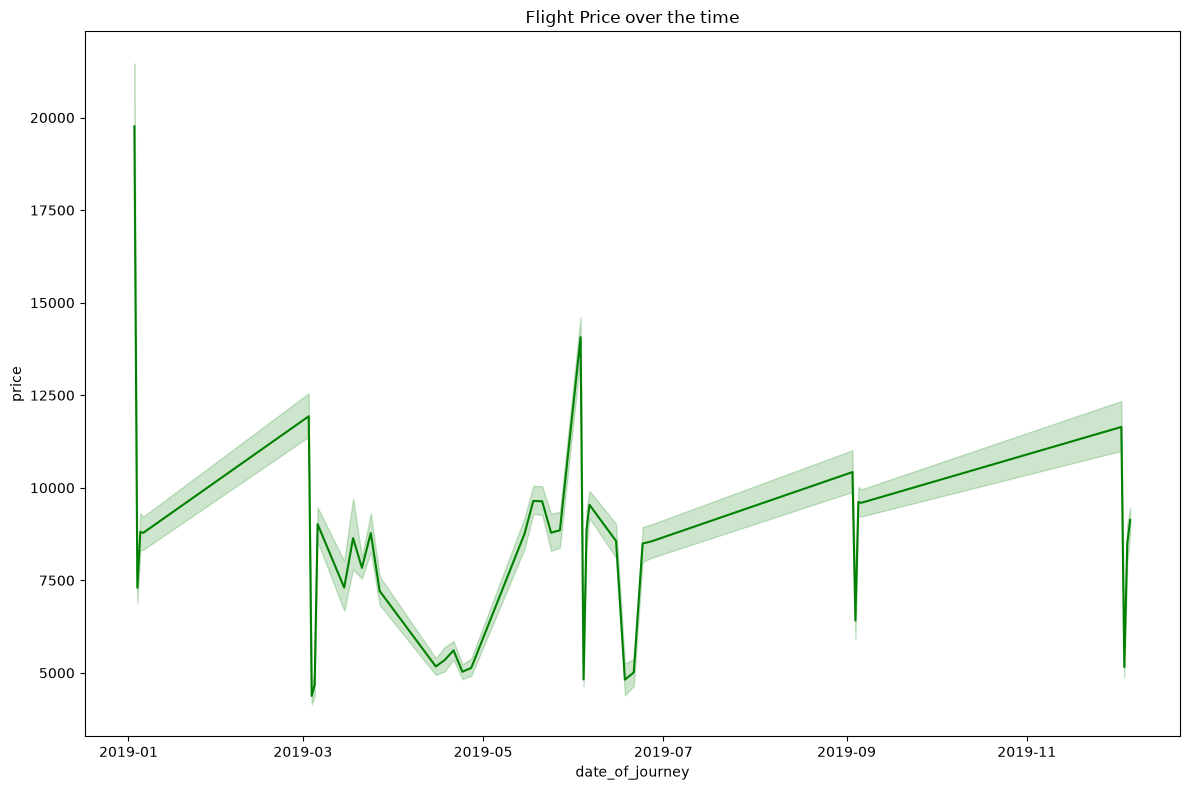

In [14]:
plt.figure(figsize=(12, 8))
sns.lineplot(data=df, x='date_of_journey', y='price', color='green')
plt.title('Flight Price over the time')
plt.tight_layout()
plt.show()

In [15]:
df['month'] = df.date_of_journey.dt.month_name()

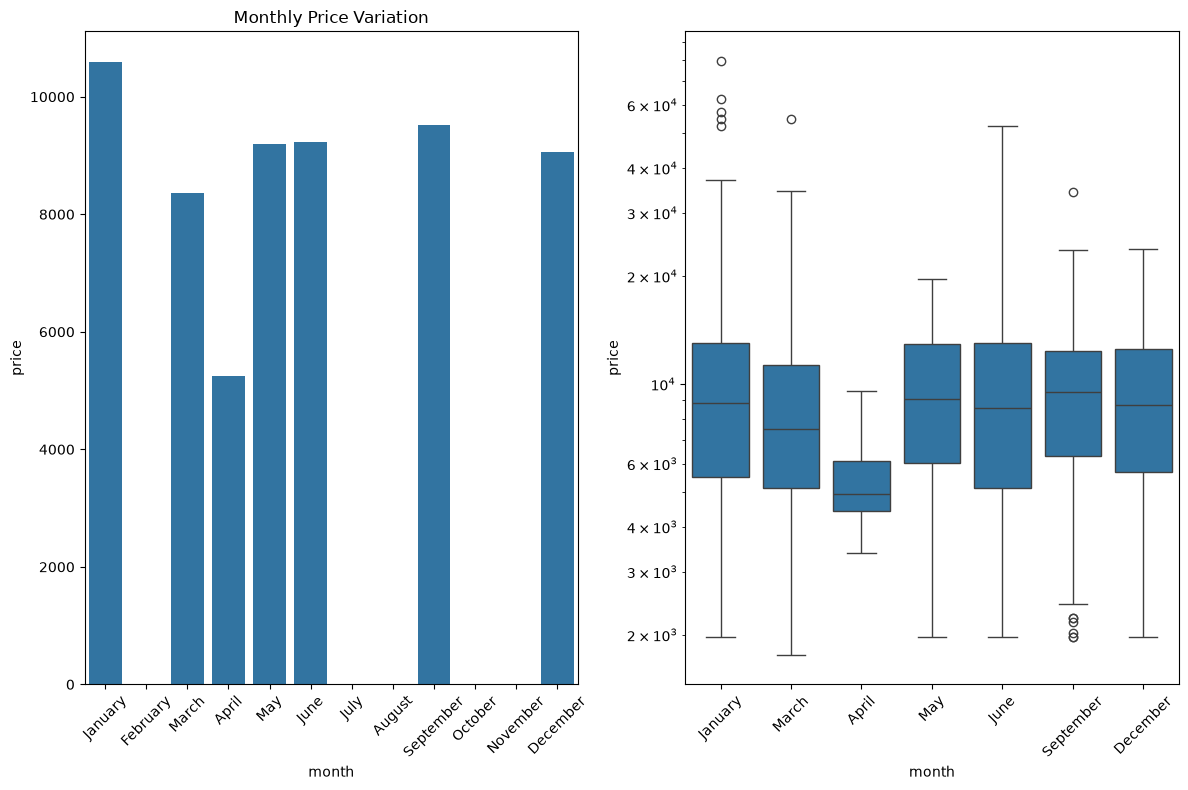

In [16]:
months = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]
plt.figure(figsize=(12, 8))
plt.subplot(1, 2, 1)
sns.barplot(df.groupby('month')['price'].mean().reindex(months))
plt.title('Monthly Price Variation')
plt.xticks(rotation=45)

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='month', y='price', log_scale=True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Source-Destination

In [17]:
df.source.unique()

<StringArray>
['Delhi', 'Banglore', 'Chennai', 'Kolkata', 'Mumbai']
Length: 5, dtype: str

In [18]:
df.destination.unique()

<StringArray>
['Cochin', 'New Delhi', 'Kolkata', 'Banglore', 'Hyderabad', 'Delhi']
Length: 6, dtype: str

In [19]:
df.destination = df.destination.replace('New Delhi', 'Delhi')

In [20]:
destination_price_data = df.groupby(['destination', 'airline'])['price'].mean()
source_price_data = df.groupby(['source', 'airline'])['price'].mean()

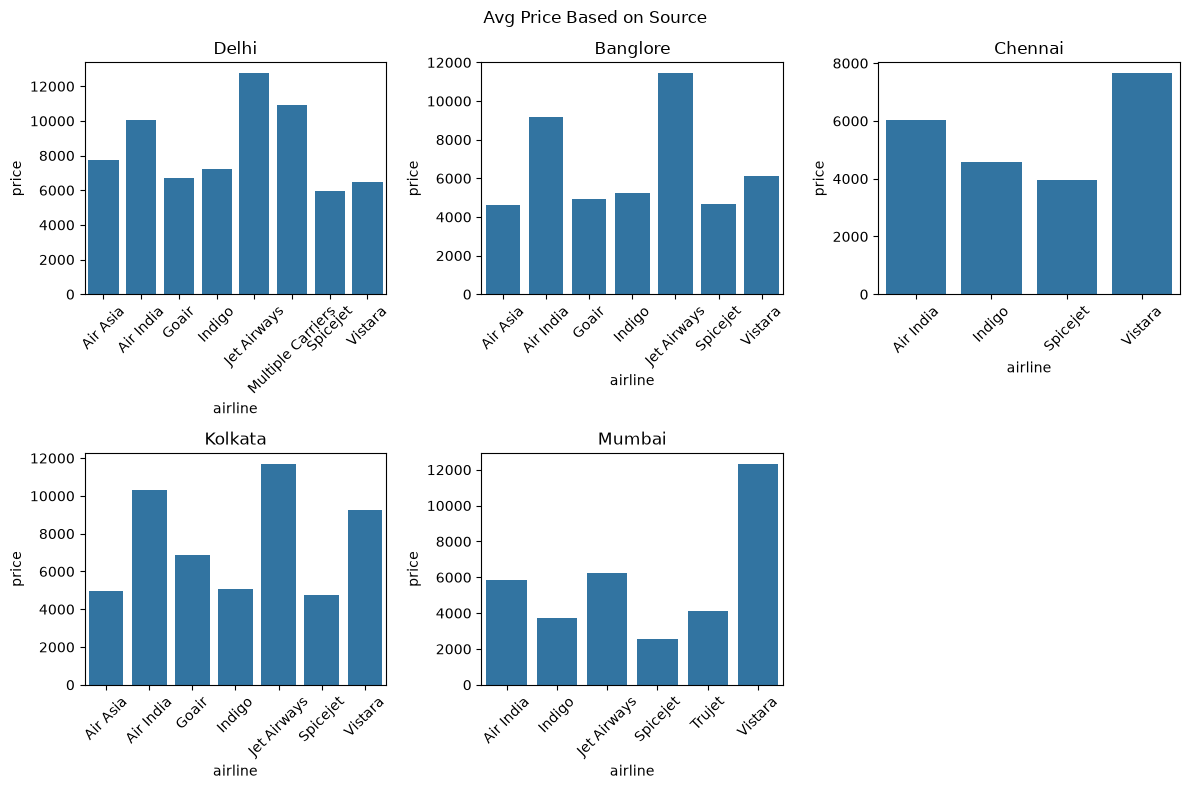

In [21]:
plt.figure(figsize=(12, 8)).suptitle('Avg Price Based on Source')
n = 0

for i in df.source.unique():

    plt.subplot(2, 3, n+1)
    sns.barplot(data=source_price_data.loc[i])
    plt.title(i)
    plt.xticks(rotation=45)

    n+= 1
    
plt.tight_layout()
plt.show()

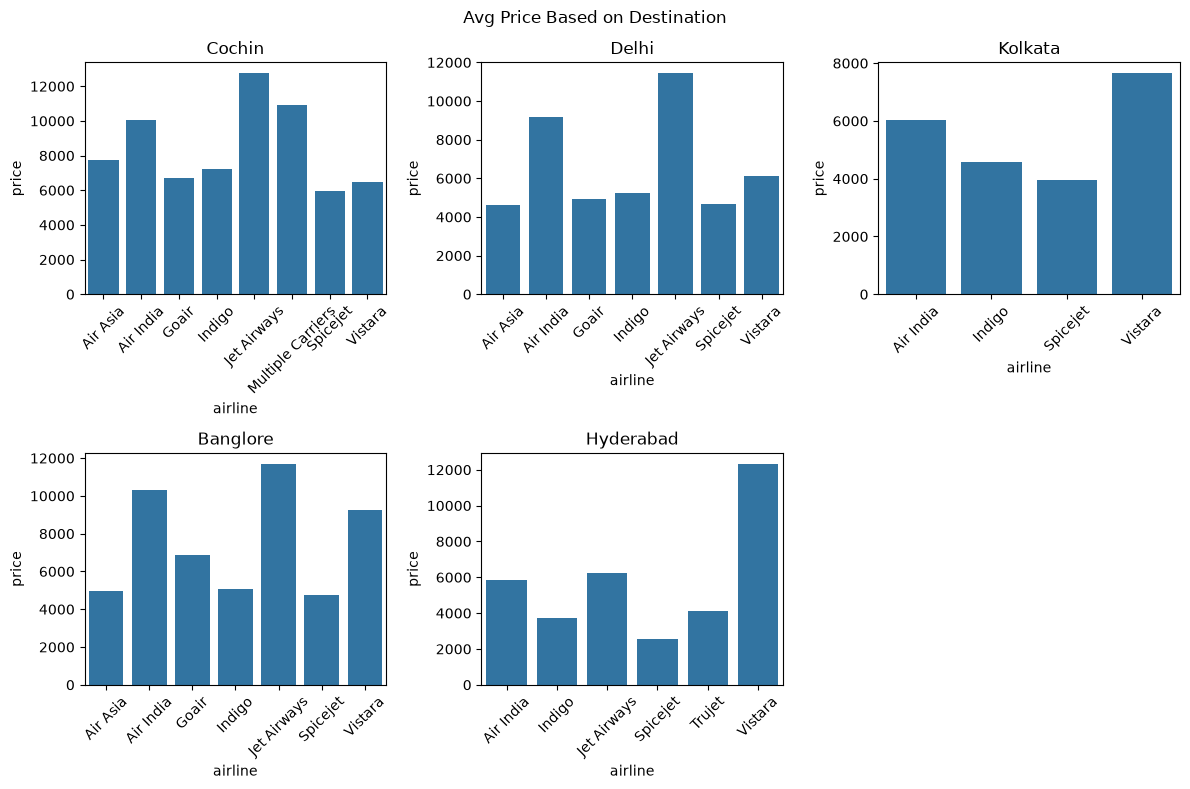

In [22]:
plt.figure(figsize=(12, 8)).suptitle('Avg Price Based on Destination')
n = 0

for i in df.destination.unique():

    plt.subplot(2, 3, n+1)
    sns.barplot(data=destination_price_data.loc[i])
    plt.title(i)
    plt.xticks(rotation=45)

    n+= 1
    
plt.tight_layout()
plt.show()

In [23]:
source_destination_price_data = df.groupby(['source', 'destination'])['price'].mean().reset_index()
source_destination_price_data['route'] = source_destination_price_data['source'] + '->' + source_destination_price_data['destination']

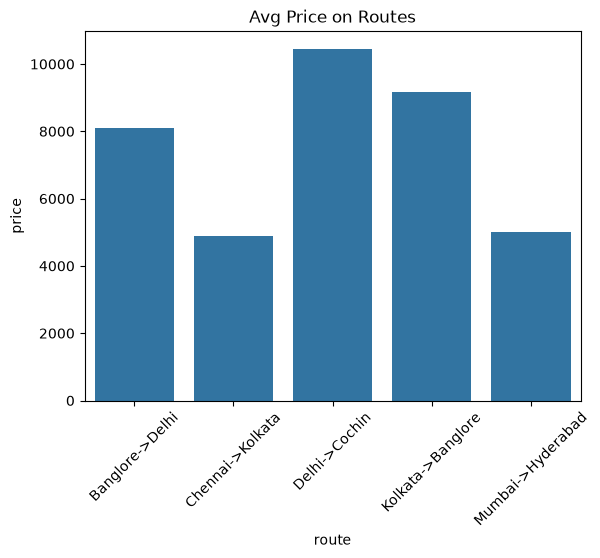

In [24]:
sns.barplot(data=source_destination_price_data, x='route', y='price')
plt.xticks(rotation=45)
plt.title('Avg Price on Routes')
plt.show()

### Departure Time

In [25]:
df.dep_time.head()

0   2026-11-01 12:50:00
1   2026-11-01 05:50:00
2   2026-11-01 22:50:00
3   2026-11-01 06:45:00
4   2026-11-01 07:55:00
Name: dep_time, dtype: datetime64[us]

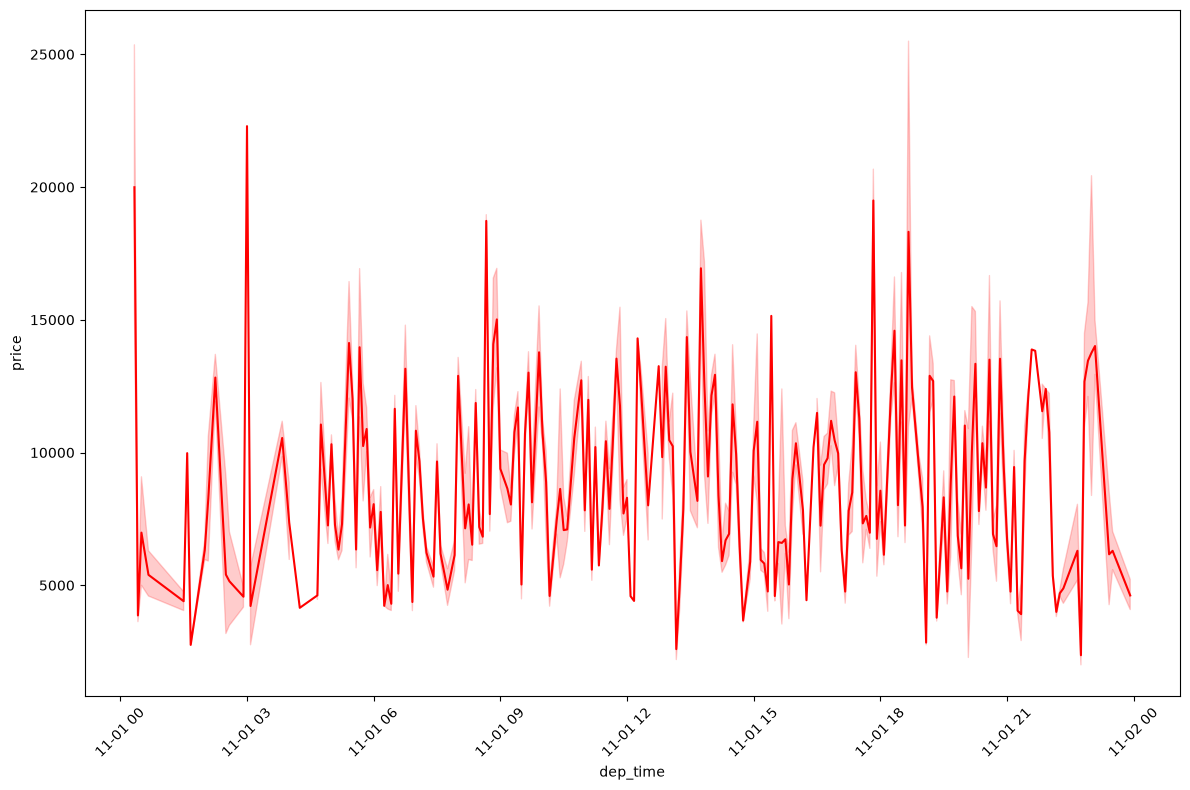

In [31]:
plt.figure(figsize=(12, 8))
sns.lineplot(data=df, x='dep_time', y='price', color='red')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [38]:
def time_period(time):

    if 5<= time < 12:
        return 'morning'
    elif 12 <= time < 18:
        return 'afternoon'
    elif 18<= time <21:
        return 'evening'
    else:
        return 'night'
        
df['dep_time_period'] = df.dep_time.dt.hour.apply(time_period)

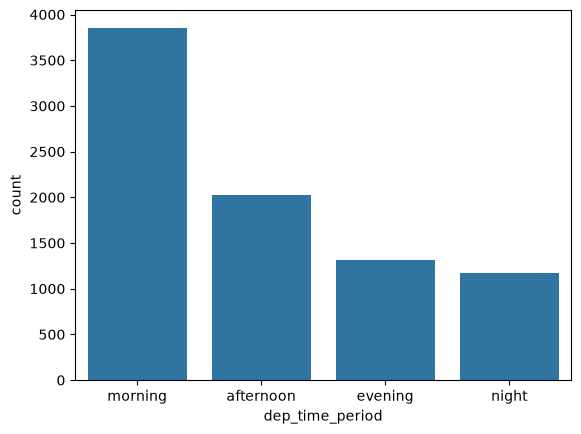

In [40]:
sns.barplot(df.dep_time_period.value_counts())
plt.show()

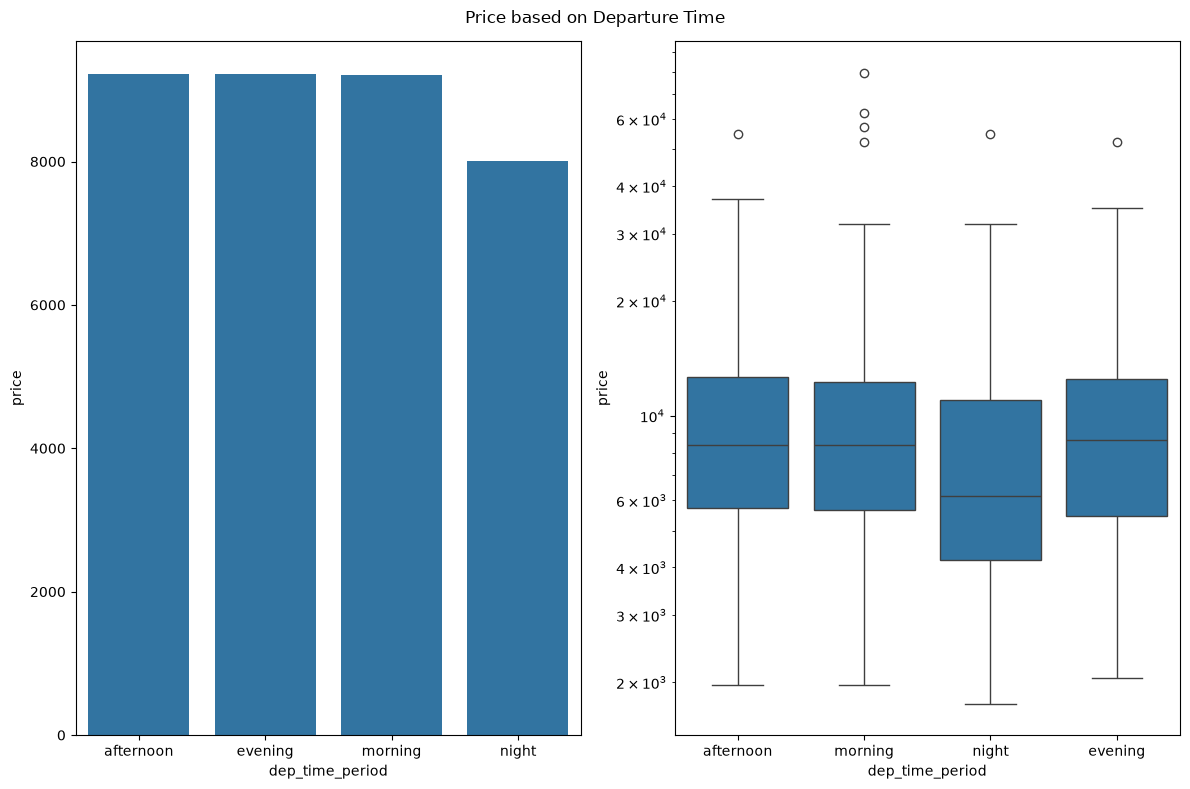

In [46]:
plt.figure(figsize=(12, 8)).suptitle('Price based on Departure Time')

plt.subplot(1, 2, 1)
sns.barplot(df.groupby('dep_time_period')['price'].mean())

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='dep_time_period', y='price', log_scale=True)

plt.tight_layout()
plt.show()

### Duration

In [47]:
df.duration

0        385
1        390
2        755
3       1600
4        140
        ... 
8364     415
8365     180
8366    1695
8367    1215
8368     570
Name: duration, Length: 8369, dtype: int64

In [48]:
df.duration.describe()

count    8369.000000
mean      628.675469
std       500.579658
min        75.000000
25%       170.000000
50%       505.000000
75%       910.000000
max      2860.000000
Name: duration, dtype: float64

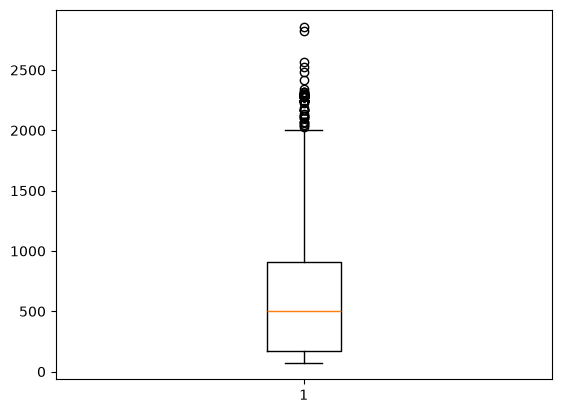

In [50]:
plt.boxplot(df.duration)
plt.show()

In [52]:
bins = [0, 180, 360, 700, float('inf')]

labels = ['short', 'medium', 'long', 'very long']

df['duration_category'] = pd.cut(
    df['duration'],
    bins=bins,
    labels=labels
)

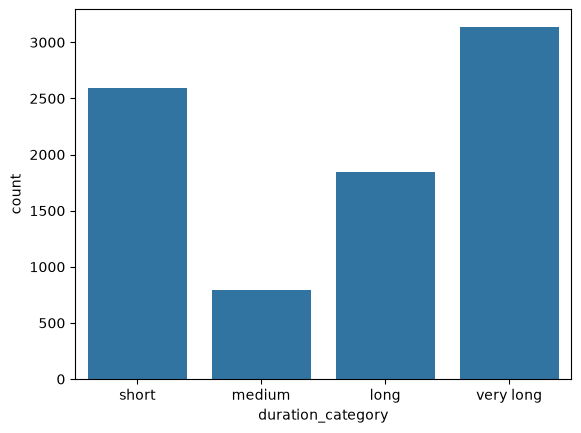

In [53]:
sns.barplot(df.duration_category.value_counts())
plt.show()

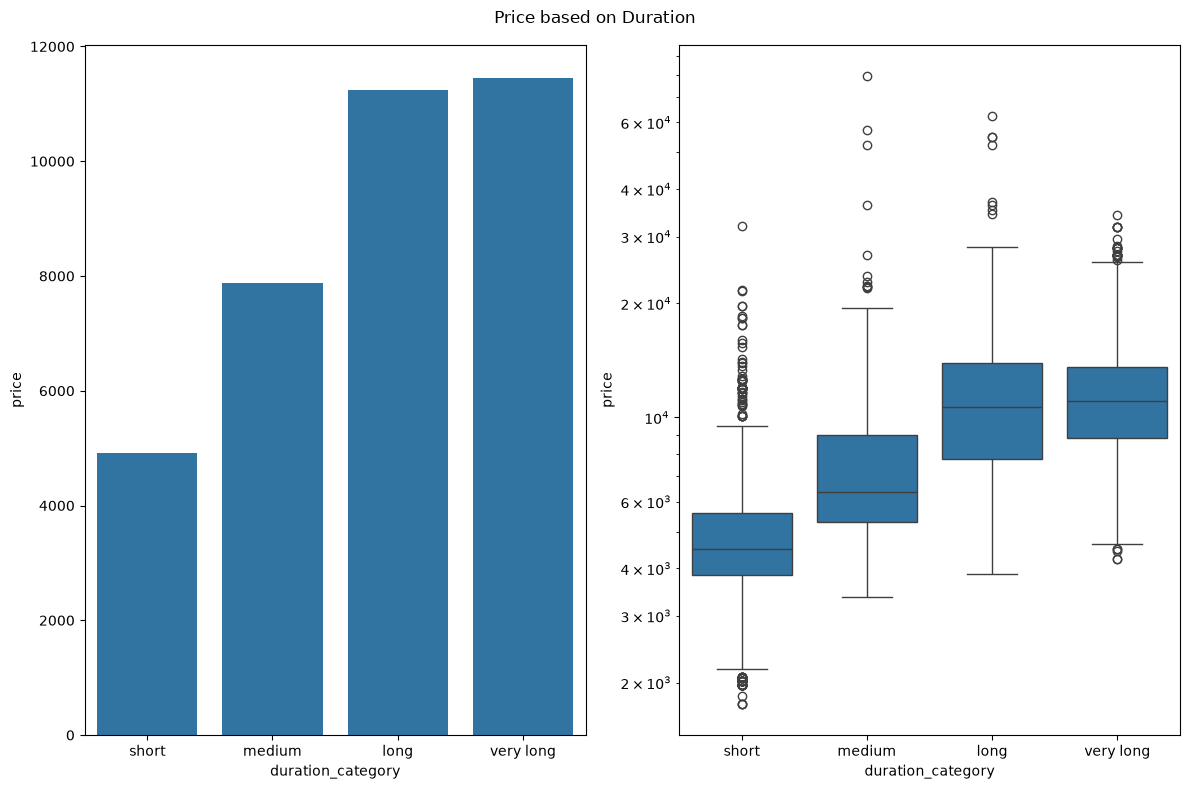

In [54]:
plt.figure(figsize=(12, 8)).suptitle('Price based on Duration')

plt.subplot(1, 2, 1)
sns.barplot(df.groupby('duration_category')['price'].mean())

plt.subplot(1, 2, 2)
sns.boxplot(data=df, x='duration_category', y='price', log_scale=True)

plt.tight_layout()
plt.show()

In [59]:
# normality test using Shapiro-wilk Test
w_state, p_value = shapiro(df.duration)
print(p_value)
if p_value > 0.05:
    print('Fail to reject H0 -> Normally Distributed')
else:
    print('Reject H0 -> Not Normally Distributed')

1.7821615835292692e-61
Reject H0 -> Not Normally Distributed


D:\Flight Price Prediction\myenv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 8369.
  res = hypotest_fun_out(*samples, **kwds)


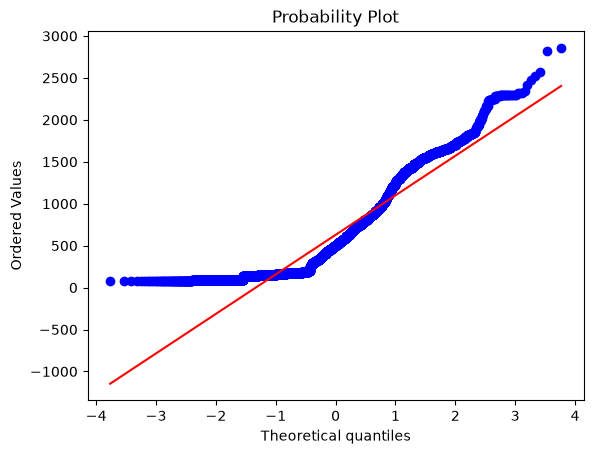

In [64]:
stats.probplot(df.duration, plot=plt, dist='norm')
plt.show()

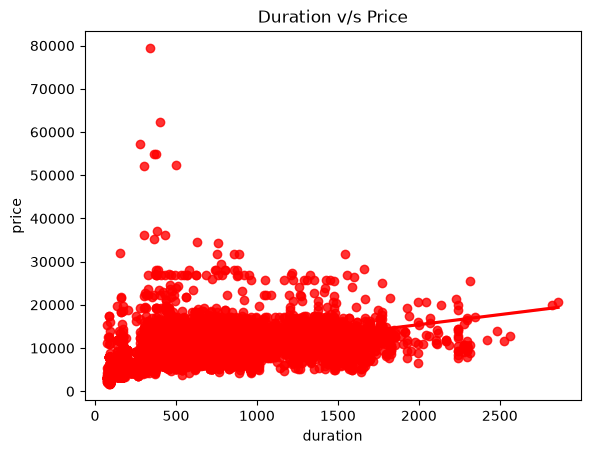

In [70]:
sns.regplot(data=df, x='duration', y='price',color='red')
plt.title('Duration v/s Price')
plt.show()

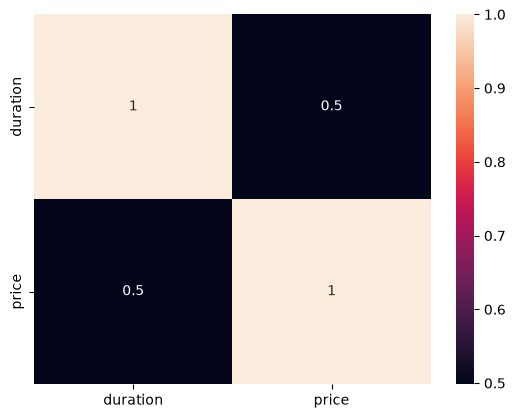

In [75]:
sns.heatmap(df[['duration', 'price']].corr(), annot=True)
plt.show()

In [77]:
# pearson test to check Correlation
corr, p_value = stats.pearsonr(df['duration'], df['price'])
print(p_value)

if p_value > 0.05:
    print('Fail to reject H0 -> Correlation is Zero')
else:
    print('Reject H0 -> Correlated')

0.0
Reject H0 -> Correlated
